In [4]:
%load_ext autoreload
%autoreload 2
%reset -f
%matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
import sys
from pathlib import Path
import pandas as pd
from lib.config import PEAKMIN_CONFIG_PARAMS_DEFAULT, FLOWRATE_CONFIG_PARAMS_DEFAULT
r2 = Path.cwd()  # keep notebook kernel cwd on Challenge_SystemHealthAlarm/r2
sys.path.insert(0, str(r2.parents[2] / "packages"))
sys.path.insert(0, str(r2))

from lib.Detector.FlowrateDetector import *
from lib.Detector.PeakMinDetector import *
from lib.Detector.FaultDetector import *
from lib.IO.AlarmDBConnection import Alarm_Conn
from lib.SurveyorLookup import get_latest_customer_per_surveyor_unit
import matplotlib.pyplot as plt

surveyor_lookup = get_latest_customer_per_surveyor_unit()
for i in range(len(surveyor_lookup)):
    customer_id = surveyor_lookup['CustomerId'].iloc[i]
    surveyor_unit_id = surveyor_lookup['SurveyorUnitId'].iloc[i]
    surveyor_unit = surveyor_lookup['SurveyorUnit'].iloc[i]
    customer_name = surveyor_lookup['CustomerName'].iloc[i]
    print('Activating detectors for', customer_name, 'customer_name:','surveyor_unit:', surveyor_unit)
    flowrate_detector = FlowRateDetector()
    flowrate_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
    flowrate_detector.load_data()
    flowrate_detector.load_config()
    flowrate_detector.run_detector(write_back=True)
    peak_detector = PeakMinDetector()
    peak_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
    peak_detector.load_data()
    peak_detector.load_config()
    peak_detector.run_detector(write_back=True)

    fault_detector = FaultDetector()
    fault_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
    fault_detector.load_data()
    fault_detector.load_config()
    fault_detector.run_detector(write_back=True)

    fault_detector = FaultDetector()
    fault_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
    fault_detector.load_data()
    fault_detector.load_config()
    fault_detector.sandbox_data
    fault_detector.run_detector(write_back=True)

Activating detectors for Avacon customer_name: surveyor_unit: Avacon Car #3
397
Running detector FlowRateDetector from index 0 to 397
397
Running detector PeakMinDetector from index 0 to 397
397
397
Running detector FaultDetector from index 0 to 397
0
0
No data to run detector FaultDetector
Activating detectors for Toscana Energia customer_name: surveyor_unit: Jeep GY377XR Fi2
332
Running detector FlowRateDetector from index 0 to 332
332
Running detector PeakMinDetector from index 0 to 332
332
332
Running detector FaultDetector from index 0 to 332
0
0
No data to run detector FaultDetector
Activating detectors for Cadent customer_name: surveyor_unit: Cadent Surveyor #18 - LP75GDE
633
Running detector FlowRateDetector from index 0 to 633
633
Running detector PeakMinDetector from index 0 to 633
633
633
Running detector FaultDetector from index 0 to 633
0
0
No data to run detector FaultDetector
Activating detectors for Energieversorgung Filstal customer_name: surveyor_unit: EVF Car #1
188


Text(0, 0.5, 'PeakMinutes')

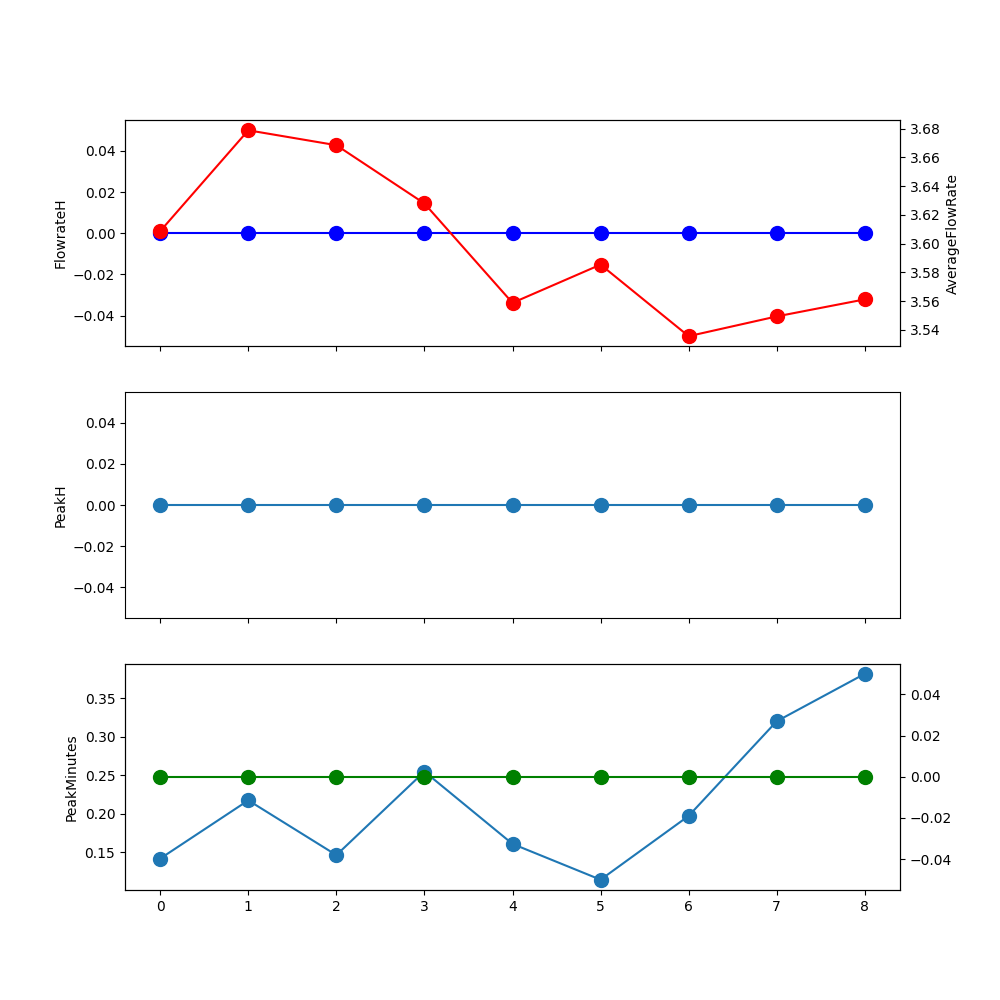

In [6]:
peak_min = peak_detector.sandbox_data['PeakH']
flowrate_h = flowrate_detector.sandbox_data['FlowrateH']
joint = peak_min * flowrate_h
peak_minutes = peak_detector.sandbox_data['PeakMinutes']
fig,ax = plt.subplots(3,1, sharex=True, figsize=(10,10))
ax00 = ax[0].twinx()
ax00.plot(flowrate_detector.sandbox_data['AverageFlowRate'], marker='o', markersize=10, color='red')
ax00.set_ylabel("AverageFlowRate")
ax[0].plot(flowrate_h, marker='o', markersize=10, color='blue')
ax[0].set_ylabel("FlowrateH")

ax[1].plot(peak_min, marker='o', markersize=10)
ax[1].set_ylabel("PeakH")
ax[2].plot(peak_minutes, marker='o', markersize=10)
ax20 = ax[2].twinx()
ax20.plot(peak_detector.sandbox_data['PeakI'], marker='o', markersize=10, color='green')
ax[2].set_ylabel("PeakMinutes")